In [1]:

# Import Path for platform-independent file paths.
from pathlib import Path

# Import Pandas for tabular data processing.
import pandas as pd

# Import NumPy for numerical operations.
import numpy as np

# Import Matplotlib for visualizations.
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations.
import seaborn as sns

# Set consistent display options for easier inspection.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Set a consistent random seed for reproducible experiments.
RANDOM_STATE = 42

print("Imports completed successfully.")


Imports completed successfully.


In [2]:

# Detect the current notebook directory.
CURRENT_DIR = Path.cwd()

# Locate the RetailAI project root.
if (CURRENT_DIR / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not find the RetailAI project root. "
        "Run this notebook from the project or notebooks directory."
    )

# Define the raw and processed data directories.
RAW_DATA_PATH = PROJECT_ROOT / "datasets" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "datasets" / "processed"

# Define the directory for reports and outputs.
REPORTS_PATH = PROJECT_ROOT / "reports"

# Create the reports directory if it does not exist.
REPORTS_PATH.mkdir(parents=True, exist_ok=True)

# Display the detected paths.
print("Project root:", PROJECT_ROOT)
print("Raw data path:", RAW_DATA_PATH)
print("Processed data path:", PROCESSED_DATA_PATH)
print("Reports path:", REPORTS_PATH)


Project root: /Users/adityachaubey/Desktop/RetailAI
Raw data path: /Users/adityachaubey/Desktop/RetailAI/datasets/raw
Processed data path: /Users/adityachaubey/Desktop/RetailAI/datasets/processed
Reports path: /Users/adityachaubey/Desktop/RetailAI/reports


In [3]:

# Load the original review dataset to preserve Portuguese review text.
reviews = pd.read_csv(
    RAW_DATA_PATH / "olist_order_reviews_dataset.csv"
)

# Load processed orders and order items.
orders = pd.read_parquet(
    PROCESSED_DATA_PATH / "orders.parquet"
)

order_items = pd.read_parquet(
    PROCESSED_DATA_PATH / "order_items.parquet"
)

# Load processed product and seller information.
products = pd.read_parquet(
    PROCESSED_DATA_PATH / "products.parquet"
)

sellers = pd.read_parquet(
    PROCESSED_DATA_PATH / "sellers.parquet"
)

# Load customer information.
customers = pd.read_parquet(
    PROCESSED_DATA_PATH / "customers.parquet"
)

# Load customer segmentation results from Notebook 02.
customer_segments = pd.read_csv(
    PROCESSED_DATA_PATH / "customer_segments.csv"
)

# Display dataset dimensions to verify successful loading.
print("Reviews:", reviews.shape)
print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)
print("Sellers:", sellers.shape)
print("Customers:", customers.shape)
print("Customer segments:", customer_segments.shape)


Reviews: (99224, 7)
Orders: (99441, 8)
Order items: (112650, 7)
Products: (32951, 9)
Sellers: (3095, 4)
Customers: (99441, 5)
Customer segments: (93358, 13)


In [4]:

# Display all available review columns.
print("Review columns:")
print(reviews.columns.tolist())

# Display the data types and non-null counts.
print("\nReview dataset information:")
reviews.info()

# Define the columns required for review intelligence.
required_review_columns = [
    "review_id",
    "order_id",
    "review_score",
    "review_comment_title",
    "review_comment_message"
]

# Identify required columns that are missing.
missing_columns = [
    column
    for column in required_review_columns
    if column not in reviews.columns
]

# Validate the review schema.
if missing_columns:
    raise ValueError(
        f"Required review columns are missing: {missing_columns}"
    )

print("\nAll required review columns are available.")


Review columns:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Review dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB

All required review columns are available.


In [5]:

# Count missing review titles and comments.
missing_title_count = reviews["review_comment_title"].isna().sum()
missing_comment_count = reviews["review_comment_message"].isna().sum()

# Identify reviews containing a title or comment.
has_title = (
    reviews["review_comment_title"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

has_comment = (
    reviews["review_comment_message"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

has_any_text = has_title | has_comment
has_both_texts = has_title & has_comment

# Summarize review text coverage.
review_text_summary = pd.DataFrame({
    "Metric": [
        "Total reviews",
        "Missing review titles",
        "Missing review comments",
        "Reviews with any text",
        "Reviews with both title and comment",
        "Reviews without any text"
    ],
    "Count": [
        len(reviews),
        missing_title_count,
        missing_comment_count,
        has_any_text.sum(),
        has_both_texts.sum(),
        (~has_any_text).sum()
    ]
})

review_text_summary["Percentage"] = (
    review_text_summary["Count"] / len(reviews) * 100
).round(2)

review_text_summary


,Metric,Count,Percentage
0,Total reviews,99224,100.000
1,Missing review titles,87656,88.340
2,Missing review comments,58247,58.700
3,Reviews with any text,42687,43.020
4,Reviews with both title and comment,9829,9.910
5,Reviews without any text,56537,56.980


In [6]:

# Replace missing review text with empty strings.
review_title = reviews["review_comment_title"].fillna("").astype(str).str.strip()
review_comment = reviews["review_comment_message"].fillna("").astype(str).str.strip()

# Combine the title and comment into one review text field.
reviews["review_text_original"] = (
    review_title + " " + review_comment
).str.strip()

# Identify reviews with usable text.
reviews["has_review_text"] = reviews["review_text_original"].ne("")

# Display text coverage after combining both fields.
print("Total reviews:", len(reviews))
print("Reviews with text:", reviews["has_review_text"].sum())
print(
    "Text coverage (%):",
    round(reviews["has_review_text"].mean() * 100, 2)
)

# Inspect examples without modifying the original text.
reviews.loc[
    reviews["has_review_text"],
    ["review_score", "review_text_original"]
].head(10)


Total reviews: 99224
Reviews with text: 42687
Text coverage (%): 43.02


,review_score,review_text_original
3,5,Recebi bem antes do prazo estipulado.
4,5,Parabéns lojas lannister adorei comprar pela I...
9,4,recomendo aparelho eficiente. no site a marca ...
12,4,"Mas um pouco ,travando...pelo valor ta Boa."
15,5,"Super recomendo Vendedor confiável, produto ok..."
16,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
19,1,Não chegou meu produto Péssimo
22,5,Ótimo Loja nota 10
24,5,obrigado pela atençao amim dispensada
27,5,A compra foi realizada facilmente.\r\nA entreg...


In [7]:

# Select reviews containing non-empty text.
text_reviews = reviews.loc[reviews["has_review_text"]].copy()

# Calculate review text length in characters and words.
text_reviews["text_char_count"] = (
    text_reviews["review_text_original"].str.len()
)

text_reviews["text_word_count"] = (
    text_reviews["review_text_original"]
    .str.split()
    .str.len()
)

# Generate descriptive statistics for review length.
display(
    text_reviews[
        ["text_char_count", "text_word_count"]
    ].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
)

# Inspect the shortest reviews.
display(
    text_reviews.sort_values("text_char_count")[
        ["review_score", "review_text_original", "text_char_count"]
    ].head(10)
)

# Inspect the longest reviews.
display(
    text_reviews.sort_values("text_char_count", ascending=False)[
        ["review_score", "review_text_original", "text_char_count"]
    ].head(10)
)


,text_char_count,text_word_count
count,"42,687.000","42,687.000"
mean,69.036,11.719
std,54.922,9.688
min,1.000,1.000
25%,27.000,4.000
50%,53.000,9.000
75%,95.000,16.000
90%,162.000,28.000
95%,193.000,33.000
max,229.000,48.000


,review_score,review_text_original,text_char_count
49002,4,8,1
4575,1,8,1
62778,3,3,1
27041,1,.,1
34584,4,?,1
42131,5,.,1
598,4,4,1
65441,5,9,1
28716,4,7,1
583,4,5,1


,review_score,review_text_original,text_char_count
12824,1,Não comprem na targaryen A empresa terceira ta...,229
60390,1,FALSIFICADO (targaryen) RECEBI UM PRODUTO F-A-...,228
73274,1,Produto de qualidade infe Bem comprei esse qua...,227
71348,2,Faltou peça e má qualidad Não gostei desta loj...,226
21275,3,Avaliando se recomendaria A cadeira é confortá...,226
72310,1,Reclamação em relação a d Está mercadoria foi ...,226
32771,4,"Chinesa Boa,Já é possível Somente uma SURPRESA...",226
82947,3,"Adaptador de 12 v p/ 110v Comprei o adaptador,...",226
87757,1,Produto de qualidade ruim Produto completament...,226
4150,1,Vendedor Sem Compromisso. Comprei 3 plafons de...,226


,review_count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


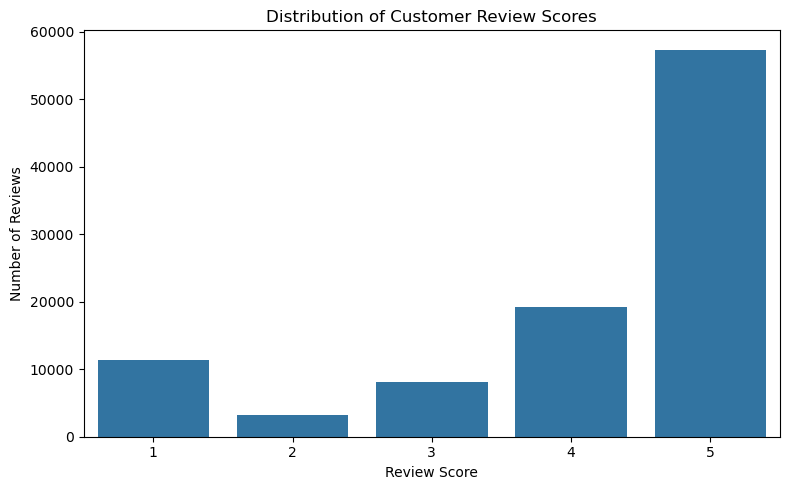

In [8]:

# Display review rating counts in ascending score order.
rating_counts = (
    reviews["review_score"]
    .value_counts(dropna=False)
    .sort_index()
)

display(rating_counts.rename("review_count").to_frame())

# Plot the review score distribution.
plt.figure(figsize=(8, 5))
sns.countplot(
    data=reviews,
    x="review_score",
    order=[1, 2, 3, 4, 5]
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


In [9]:

# Calculate the count of each review score.
score_counts = (
    reviews["review_score"]
    .value_counts()
    .reindex([1, 2, 3, 4, 5], fill_value=0)
    .rename_axis("review_score")
    .reset_index(name="review_count")
)

# Calculate each score's percentage of all reviews.
score_counts["percentage"] = (
    score_counts["review_count"] / len(reviews) * 100
).round(2)

# Calculate overall rating statistics.
mean_rating = reviews["review_score"].mean()
median_rating = reviews["review_score"].median()

display(score_counts)

print(f"Mean review score: {mean_rating:.2f}")
print(f"Median review score: {median_rating:.2f}")


,review_score,review_count,percentage
0,1,11424,11.510
1,2,3151,3.180
2,3,8179,8.240
3,4,19142,19.290
4,5,57328,57.780


Mean review score: 4.09
Median review score: 5.00


In [10]:

# Compare rating distributions for reviews with and without text.
reviews["text_group"] = np.where(
    reviews["has_review_text"],
    "With text",
    "Without text"
)

rating_by_text = (
    reviews.groupby("text_group", observed=True)
    .agg(
        review_count=("review_score", "size"),
        mean_rating=("review_score", "mean"),
        median_rating=("review_score", "median"),
        low_rating_rate=("review_score", lambda s: (s <= 2).mean() * 100)
    )
    .round(2)
)

display(rating_by_text)


,review_count,mean_rating,median_rating,low_rating_rate
text_group,,,,
With text,42687,3.700,5.000,25.750
Without text,56537,4.380,5.000,6.330


In [12]:
# Create a dataset containing only reviews with actual text.
review_nlp = reviews.loc[
    reviews["has_review_text"],
    [
        "review_id",
        "order_id",
        "review_score",
        "review_comment_title",
        "review_comment_message",
        "review_text_original"
    ]
].copy()

# Remove duplicate review-order combinations.
review_nlp = review_nlp.drop_duplicates(
    subset=["review_id", "order_id"]
).reset_index(drop=True)

# Display dataset information.
print("NLP dataset shape:", review_nlp.shape)
print("Unique review IDs:", review_nlp["review_id"].nunique())
print("Unique order IDs:", review_nlp["order_id"].nunique())
print("Missing review text:", review_nlp["review_text_original"].isna().sum())

NLP dataset shape: (42687, 6)
Unique review IDs: 42370
Unique order IDs: 42540
Missing review text: 0


In [13]:
# Inspect real customer reviews with their original ratings.
sample_reviews = (
    review_nlp[
        ["review_score", "review_text_original"]
    ]
    .sample(
        n=min(20, len(review_nlp)),
        random_state=RANDOM_STATE
    )
    .reset_index(drop=True)
)

display(sample_reviews)

,review_score,review_text_original
0,5,Os potes de mantimentos são lindíssimos! Estou...
1,4,"Satisfeito Demorou para chegar, mas o produto ..."
2,3,comprei 2 mangueiras e veio apenas 1
3,5,Produto de qualidade e entrega antes do prazo
4,5,Atendemento Otimo Entrega Antes do praso E pro...
5,5,Produto ótimo e entregue beem antes do prazo .
6,5,"Entrega super rápida, muito antes do prazo. Pr..."
7,5,Entrega antes da data.
8,5,Ótimo preço A entrega poderia ser em 5 dias. O...
9,4,foi entregue no prazo


In [14]:
# Normalize Unicode characters and remove unnecessary whitespace.
review_nlp["review_text_clean"] = (
    review_nlp["review_text_original"]
    .str.normalize("NFKC")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Keep only non-empty cleaned reviews.
review_nlp = review_nlp.loc[
    review_nlp["review_text_clean"].ne("")
].copy()

# Display cleaned text examples.
display(
    review_nlp[
        ["review_text_original", "review_text_clean"]
    ].head(10)
)

print("Usable NLP reviews:", len(review_nlp))
print(
    "Empty cleaned reviews:",
    review_nlp["review_text_clean"].eq("").sum()
)

,review_text_original,review_text_clean
0,Recebi bem antes do prazo estipulado.,Recebi bem antes do prazo estipulado.
1,Parabéns lojas lannister adorei comprar pela I...,Parabéns lojas lannister adorei comprar pela I...
2,recomendo aparelho eficiente. no site a marca ...,recomendo aparelho eficiente. no site a marca ...
3,"Mas um pouco ,travando...pelo valor ta Boa.","Mas um pouco ,travando...pelo valor ta Boa."
4,"Super recomendo Vendedor confiável, produto ok...","Super recomendo Vendedor confiável, produto ok..."
5,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...","GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E..."
6,Não chegou meu produto Péssimo,Não chegou meu produto Péssimo
7,Ótimo Loja nota 10,Ótimo Loja nota 10
8,obrigado pela atençao amim dispensada,obrigado pela atençao amim dispensada
9,A compra foi realizada facilmente.\r\nA entreg...,A compra foi realizada facilmente. A entrega f...


Usable NLP reviews: 42687
Empty cleaned reviews: 0


In [15]:
%pip install -U transformers sentence-transformers torch

  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 1.4 MB/s eta 0:00:00a 0:00:01
Using cached click-8.5.0-py3-none-any.whl (125 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 2.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 2.4 MB/s eta 0:00:00-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 1.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.3/127.3 MB 4.2 MB/s eta 0:00:0000:0100:01
Using cached anyio-4.15.1-py3-none-any.whl (132 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB

In [1]:
# Verify the NLP environment and package versions.
import sys
import torch
import transformers
import sentence_transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)
print("\nNLP imports successful!")

/opt/anaconda3/envs/retailai-nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: 3.11.17 (main, Oct  1 2026, 20:09:52) [Clang 20.1.8 ]
PyTorch: 2.5.1
Transformers: 4.44.2
Sentence Transformers: 3.3.1

NLP imports successful!


In [2]:
# Load the multilingual sentiment analysis model.
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification

SENTIMENT_MODEL_NAME = "clapAI/roberta-base-multilingual-sentiment"

sentiment_tokenizer = AutoTokenizer.from_pretrained(
    SENTIMENT_MODEL_NAME
)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    SENTIMENT_MODEL_NAME
)

# Display the sentiment labels supported by the model.
print("Model loaded:", SENTIMENT_MODEL_NAME)
print("Model labels:", sentiment_model.config.id2label)

Model loaded: clapAI/roberta-base-multilingual-sentiment
Model labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


In [3]:
# Create a sentiment analysis pipeline.
sentiment_pipeline = pipeline(
    "text-classification",
    model=sentiment_model,
    tokenizer=sentiment_tokenizer,
    device=-1
)

# Test the model on a few Portuguese customer reviews.
test_texts = [
    "Produto excelente, gostei muito!",
    "Não gostei do produto, chegou quebrado.",
    "O produto chegou ontem."
]

test_predictions = sentiment_pipeline(
    test_texts,
    truncation=True,
    max_length=256
)

# Display the predictions and confidence scores.
for text, prediction in zip(test_texts, test_predictions):
    print(f"\nReview: {text}")
    print(f"Predicted sentiment: {prediction['label']}")
    print(f"Confidence: {prediction['score']:.3f}")


Review: Produto excelente, gostei muito!
Predicted sentiment: positive
Confidence: 0.969

Review: Não gostei do produto, chegou quebrado.
Predicted sentiment: negative
Confidence: 0.963

Review: O produto chegou ontem.
Predicted sentiment: neutral
Confidence: 0.635


In [1]:
# Reload the project datasets after switching the Jupyter kernel.
from pathlib import Path
import pandas as pd
import numpy as np

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError("Could not locate the RetailAI project root.")

RAW_DATA_PATH = PROJECT_ROOT / "datasets" / "raw"
PROCESSED_DATA_PATH = PROJECT_ROOT / "datasets" / "processed"

# Load the original review data.
reviews = pd.read_csv(
    RAW_DATA_PATH / "olist_order_reviews_dataset.csv"
)

# Rebuild the combined review text.
review_title = (
    reviews["review_comment_title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

review_comment = (
    reviews["review_comment_message"]
    .fillna("")
    .astype(str)
    .str.strip()
)

reviews["review_text_original"] = (
    review_title + " " + review_comment
).str.strip()

reviews["has_review_text"] = (
    reviews["review_text_original"].ne("")
)

# Keep reviews that contain actual text.
review_nlp = reviews.loc[
    reviews["has_review_text"],
    [
        "review_id",
        "order_id",
        "review_score",
        "review_comment_title",
        "review_comment_message",
        "review_text_original",
    ],
].copy()

review_nlp = (
    review_nlp
    .drop_duplicates(subset=["review_id", "order_id"])
    .reset_index(drop=True)
)

# Normalize whitespace while preserving Portuguese accents and negations.
review_nlp["review_text_clean"] = (
    review_nlp["review_text_original"]
    .str.normalize("NFKC")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

review_nlp = review_nlp.loc[
    review_nlp["review_text_clean"].ne("")
].copy()

print("Project root:", PROJECT_ROOT)
print("NLP dataset shape:", review_nlp.shape)
print("Usable reviews:", len(review_nlp))

Project root: /Users/adityachaubey/Desktop/RetailAI
NLP dataset shape: (42687, 7)
Usable reviews: 42687


In [2]:
# Check whether the current kernel has the required variables.
print("review_nlp exists:", "review_nlp" in globals())
print("sentiment_pipeline exists:", "sentiment_pipeline" in globals())

if "review_nlp" in globals():
    print("Review dataset shape:", review_nlp.shape)
    print("Clean text column exists:", "review_text_clean" in review_nlp.columns)

review_nlp exists: False
sentiment_pipeline exists: False


In [3]:
# Verify the data-processing libraries.
import sys
import pandas as pd
import numpy as np
import pyarrow
import sklearn

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("PyArrow:", pyarrow.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Data libraries are ready!")

Python: /opt/anaconda3/envs/retailai-nlp/bin/python
Pandas: 3.0.6
NumPy: 2.4.6
PyArrow: 26.0.0
Scikit-learn: 1.9.1
Data libraries are ready!


In [7]:
# Load the multilingual sentiment model.
from transformers import (
    pipeline,
    AutoTokenizer,
    AutoModelForSequenceClassification,
)

SENTIMENT_MODEL_NAME = "clapAI/roberta-base-multilingual-sentiment"

sentiment_tokenizer = AutoTokenizer.from_pretrained(
    SENTIMENT_MODEL_NAME
)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    SENTIMENT_MODEL_NAME
)

sentiment_pipeline = pipeline(
    "text-classification",
    model=sentiment_model,
    tokenizer=sentiment_tokenizer,
    device=-1,
)

print("Sentiment pipeline loaded successfully!")
print("Model labels:", sentiment_model.config.id2label)

Sentiment pipeline loaded successfully!
Model labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


In [8]:
# Reload the review dataset in the active notebook kernel.
from pathlib import Path
import pandas as pd
import numpy as np

# Locate the RetailAI project root.
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "datasets").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "RetailAI project root not found. Open the notebook from the project."
    )

RAW_DATA_PATH = PROJECT_ROOT / "datasets" / "raw"

# Load the original review data.
reviews = pd.read_csv(
    RAW_DATA_PATH / "olist_order_reviews_dataset.csv"
)

# Combine the review title and message without removing negations.
review_title = (
    reviews["review_comment_title"].fillna("").astype(str).str.strip()
)
review_comment = (
    reviews["review_comment_message"].fillna("").astype(str).str.strip()
)

reviews["review_text_original"] = (
    review_title + " " + review_comment
).str.strip()

reviews["has_review_text"] = reviews["review_text_original"].ne("")

# Create the NLP dataset.
review_nlp = reviews.loc[
    reviews["has_review_text"],
    [
        "review_id",
        "order_id",
        "review_score",
        "review_comment_title",
        "review_comment_message",
        "review_text_original",
    ],
].copy()

review_nlp = (
    review_nlp
    .drop_duplicates(subset=["review_id", "order_id"])
    .reset_index(drop=True)
)

# Normalize text while preserving Portuguese accents.
review_nlp["review_text_clean"] = (
    review_nlp["review_text_original"]
    .str.normalize("NFKC")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

review_nlp = review_nlp.loc[
    review_nlp["review_text_clean"].ne("")
].copy()

print("Project root:", PROJECT_ROOT)
print("NLP dataset shape:", review_nlp.shape)
print("Usable reviews:", len(review_nlp))

Project root: /Users/adityachaubey/Desktop/RetailAI
NLP dataset shape: (42687, 7)
Usable reviews: 42687


In [9]:
# Run sentiment analysis on all reviews with available text.
import numpy as np
from tqdm.auto import tqdm

# Prepare the review texts for inference.
review_texts = review_nlp["review_text_clean"].astype(str).tolist()

batch_size = 32
all_predictions = []

# Process reviews in batches.
for start in tqdm(range(0, len(review_texts), batch_size)):
    batch_texts = review_texts[start:start + batch_size]

    batch_predictions = sentiment_pipeline(
        batch_texts,
        batch_size=batch_size,
        truncation=True,
        max_length=256
    )

    all_predictions.extend(batch_predictions)

# Store sentiment labels and confidence scores.
review_nlp["sentiment"] = [
    prediction["label"].lower()
    for prediction in all_predictions
]

review_nlp["sentiment_confidence"] = [
    prediction["score"]
    for prediction in all_predictions
]

print("Reviews processed:", len(review_nlp))
print("\nSentiment distribution:")
display(review_nlp["sentiment"].value_counts().to_frame("review_count"))

print("\nSample predictions:")
display(
    review_nlp[
        ["review_score", "review_text_clean", "sentiment", "sentiment_confidence"]
    ].head(10)
)

100%|██████████| 1334/1334 [32:44<00:00,  1.47s/it] 


Reviews processed: 42687

Sentiment distribution:


,review_count
sentiment,
positive,22371
negative,11772
neutral,8544



Sample predictions:


,review_score,review_text_clean,sentiment,sentiment_confidence
0,5,Recebi bem antes do prazo estipulado.,positive,0.544173
1,5,Parabéns lojas lannister adorei comprar pela I...,positive,0.911989
2,4,recomendo aparelho eficiente. no site a marca ...,neutral,0.671413
3,4,"Mas um pouco ,travando...pelo valor ta Boa.",neutral,0.652884
4,5,"Super recomendo Vendedor confiável, produto ok...",positive,0.824436
5,2,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",negative,0.817349
6,1,Não chegou meu produto Péssimo,negative,0.997292
7,5,Ótimo Loja nota 10,positive,0.990210
8,5,obrigado pela atençao amim dispensada,positive,0.778531
9,5,A compra foi realizada facilmente. A entrega f...,positive,0.773898
